**`Fork`** 依赖状态图的 **`update_state()`** 方法

**示例如下**

```python
change_input_config = graph.update_state(
    config=before_router_config.config,
    values={"user_input": "帮我写一个关于布偶猫的笑话"},
    as_node=START
)
```

**其中**：

- **`config`**：历史检查点的配置信息，通常包含 **`thread_id`**、**`checkpoint_ns`** 和 **`checkpoint_id`**。**`LangGraph`** 会据此检索历史检查点

- **`values`**：要应用到该检查点上的状态更新

- **`as_node`**：指定这次状态更新应当被视为哪个节点产生的输出。

  **`LangGraph`** 会按照该节点的写入逻辑，将 **`values`** 写入状态通道，并据此决定后续从哪些节点继续执行。

  基于分叉检查点运行时，并不是重新执行 **`as_node`** 本身，而是从它的后继节点继续推进

  如 **`START`** 所属超步编号为 **`0`**，则恢复时从编号为 **`1`** 的超步开始运行。

**注意**

> **`update_state()`** 不会修改原来的历史检查点，而是基于某个历史检查点创建一个新的检查点。这个新检查点相当于一条新的执行分支。

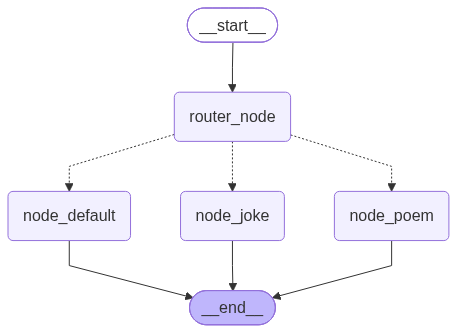

2026-10-22 23:08:29.229 | INFO     | __main__:router_node:36 - 路由节点已执行
2026-10-22 23:08:33.229 | INFO     | __main__:router_node:41 - 路由结果-res：{'topic': '布偶猫', 'mode': 'poem'}
2026-10-22 23:08:33.231 | INFO     | __main__:router:45 - 路由函数已执行
2026-10-22 23:08:33.231 | INFO     | __main__:router:47 - 路由至 node_poem 节点
2026-10-22 23:08:33.232 | INFO     | __main__:node_poem:56 - node_poem 已执行


{'username': '晓航', 'user_input': '帮我写一首关于布偶猫的七言绝句', 'output': '懒倚窗前雪作裘，\n蓝瞳湛湛似星流。\n随人解缚浑无骨，\n一任温柔抱里留。'}


In [2]:
from typing import TypedDict, Annotated, Literal
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage
from langgraph.checkpoint.memory import InMemorySaver
from langchain.chat_models import init_chat_model
from loguru import logger
from dotenv import load_dotenv
from IPython.display import display
from langgraph.config import RunnableConfig
import os

load_dotenv(override=True)

qwen_model = init_chat_model(
    model="qwen3.7-flash",
    model_provider="openai",
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url=os.getenv("DASHSCOPE_BASE_URL"),
)

# 全局状态
class OverAllState(TypedDict):
    username: str
    user_input: str
    output: str

# 私有状态
class StructuredOutputState(TypedDict):
    topic: Annotated[str,"主题"]
    mode: Annotated[Literal["poem", "joke"], "模式"]


model_with_structure = qwen_model.with_structured_output(schema=StructuredOutputState)

def router_node(state: OverAllState) -> StructuredOutputState:
    logger.info("路由节点已执行")
    user_input = state["user_input"]
    res = model_with_structure.invoke(
        [HumanMessage(user_input)],
    )
    logger.info("路由结果-res：{}",res)
    return res

def router(state: StructuredOutputState) -> Literal["node_poem", "node_joke", "node_default"]:
    logger.info("路由函数已执行")
    if state["mode"] == "poem":
        logger.info("路由至 node_poem 节点")
        return "node_poem"
    elif state["mode"] == "joke":
        logger.info("路由至 node_joke 节点")
        return "node_joke"
    logger.info("路由至兜底节点")
    return "node_default"

def node_poem(state: StructuredOutputState) -> OverAllState:
    logger.info(f"node_poem 已执行")
    topic = state["topic"]
    poem = qwen_model.invoke([HumanMessage(f"写一首关于 {topic} 的七言绝句，不要赏析，只给诗句即可")]).content
    return {
        "output": poem
    }

def node_joke(state: StructuredOutputState) -> OverAllState:
    logger.info(f"node_joke 已执行")
    topic = state["topic"]
    joke = qwen_model.invoke([HumanMessage(f"写一个关于 {topic} 的笑话，尽可能简单，不超过一百字")]).content
    return {
        "output": joke
    }

def node_default(state: StructuredOutputState) -> OverAllState:
    logger.info(f"node_default 已执行")
    return {
        "output": "无法处理的任务类型"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("router_node", router_node)
builder.add_node("node_poem", node_poem)
builder.add_node("node_joke", node_joke)
builder.add_node("node_default", node_default)

builder.add_edge(START, "router_node")
builder.add_conditional_edges(
    source="router_node",
    path=router,
    path_map=["node_poem", "node_joke", "node_default"],
)
builder.add_edge("node_poem", END)
builder.add_edge("node_joke", END)
builder.add_edge("node_default", END)

checkpointer = InMemorySaver()
myconfig: RunnableConfig = RunnableConfig(
    configurable={
        "thread_id": "123"
    }
)
graph = builder.compile(checkpointer=checkpointer)
display(graph)

resp = graph.invoke({
    "username": "晓航",
    "user_input": "帮我写一首关于布偶猫的七言绝句"
}, config=myconfig)
print(resp)

In [4]:
from rich import print as rprint
history_checkpoints = list(graph.get_state_history(config=myconfig))
rprint(history_checkpoints)

[
    StateSnapshot(
        values={
            'username': '晓航',
            'user_input': '帮我写一首关于布偶猫的七言绝句',
            'output': '懒倚窗前雪作裘，\n蓝瞳湛湛似星流。\n随人解缚浑无骨，\n一任温柔抱里留。',
            'topic': '布偶猫',
            'mode': 'poem'
        },
        next=(),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1ce2a7-fb28-63ff-8002-7aa998966d04'
            }
        },
        metadata={'source': 'loop', 'step': 2, 'parents': {}},
        created_at='2026-10-22T15:08:55.154995+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1ce2a7-2a15-666c-8001-4a4461dd8b84'
            }
        },
        tasks=(),
        interrupts=()
    ),
    StateSnapshot(
        values={
            'username': '晓航',
            'user_input': '帮我写一首关于布偶猫的七言绝句',
            'topic': '布偶猫',
            'mode': 'poem'
        },
        next=('node_poem',),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1ce2a7-2a15-666c-8001-4a4461dd8b84'
            }
        },
        metadata={'source': 'loop', 'step': 1, 'parents': {}},
        created_at='2026-10-22T15:08:33.232036+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1ce2a7-03e8-6c0d-8000-b453ac8a4d4d'
            }
        },
        tasks=(
            PregelTask(
                id='f8c9cfce-bb9c-d714-c4c6-c60e47bae726',
                name='node_poem',
                path=('__pregel_pull', 'node_poem'),
                error=None,
                interrupts=(),
                state=None,
                result={'output': '懒倚窗前雪作裘，\n蓝瞳湛湛似星流。\n随人解缚浑无骨，\n一任温柔抱里留。'}
            ),
        ),
        interrupts=()
    ),
    StateSnapshot(
        values={'username': '晓航', 'user_input': '帮我写一首关于布偶猫的七言绝句'},
        next=('router_node',),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1ce2a7-03e8-6c0d-8000-b453ac8a4d4d'
            }
        },
        metadata={'source': 'loop', 'step': 0, 'parents': {}},
        created_at='2026-10-22T15:08:29.229159+00:00',
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1ce2a7-03e7-68b9-bfff-86b56e557494'
            }
        },
        tasks=(
            PregelTask(
                id='5fa4211b-f7b0-00f0-ac91-56253d1fa7c8',
                name='router_node',
                path=('__pregel_pull', 'router_node'),
                error=None,
                interrupts=(),
                state=None,
                result={'topic': '布偶猫', 'mode': 'poem'}
            ),
        ),
        interrupts=()
    ),
    StateSnapshot(
        values={},
        next=('__start__',),
        config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1ce2a7-03e7-68b9-bfff-86b56e557494'
            }
        },
        metadata={'source': 'input', 'step': -1, 'parents': {}},
        created_at='2026-10-22T15:08:29.228664+00:00',
        parent_config=None,
        tasks=(
            PregelTask(
                id='9aa27999-bea3-5570-6738-f4bbbe6bdfdd',
                name='__start__',
                path=('__pregel_pull', '__start__'),
                error=None,
                interrupts=(),
                state=None,
                result={'username': '晓航', 'user_input': '帮我写一首关于布偶猫的七言绝句'}
            ),
        ),
        interrupts=()
    )
]

In [8]:
before_router_checkpoint = next(h for h in history_checkpoints if h.next == ('router_node',))
rprint(before_router_checkpoint)

StateSnapshot(
    values={'username': '晓航', 'user_input': '帮我写一首关于布偶猫的七言绝句'},
    next=('router_node',),
    config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1ce2a7-03e8-6c0d-8000-b453ac8a4d4d'
        }
    },
    metadata={'source': 'loop', 'step': 0, 'parents': {}},
    created_at='2026-10-22T15:08:29.229159+00:00',
    parent_config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1ce2a7-03e7-68b9-bfff-86b56e557494'
        }
    },
    tasks=(
        PregelTask(
            id='5fa4211b-f7b0-00f0-ac91-56253d1fa7c8',
            name='router_node',
            path=('__pregel_pull', 'router_node'),
            error=None,
            interrupts=(),
            state=None,
            result={'topic': '布偶猫', 'mode': 'poem'}
        ),
    ),
    interrupts=()
)

In [9]:
change_input_config = graph.update_state(
    config=before_router_checkpoint.config,
    values={"user_input": "帮我写一个关于布偶猫的笑话"},
    as_node=START
)
rprint(change_input_config)

{
    'configurable': {
        'thread_id': '123',
        'checkpoint_ns': '',
        'checkpoint_id': '1f1ce2cb-94c4-6240-8001-e039a35bf2ac'
    }
}

In [11]:
rprint(graph.get_state(change_input_config))

StateSnapshot(
    values={'username': '晓航', 'user_input': '帮我写一个关于布偶猫的笑话'},
    next=('router_node',),
    config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1ce2cb-94c4-6240-8001-e039a35bf2ac'
        }
    },
    metadata={'source': 'update', 'step': 1, 'parents': {}},
    created_at='2026-10-22T15:24:50.786156+00:00',
    parent_config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1ce2a7-03e8-6c0d-8000-b453ac8a4d4d'
        }
    },
    tasks=(
        PregelTask(
            id='b91a292c-115a-bbe0-3f44-4d990f2b2617',
            name='router_node',
            path=('__pregel_pull', 'router_node'),
            error=None,
            interrupts=(),
            state=None,
            result=None
        ),
    ),
    interrupts=()
)

In [12]:
graph.invoke(None, change_input_config)

2026-10-22 23:26:07.450 | INFO     | __main__:router_node:36 - 路由节点已执行
2026-10-22 23:26:22.463 | INFO     | __main__:router_node:41 - 路由结果-res：{'topic': '布偶猫', 'mode': 'joke'}
2026-10-22 23:26:22.464 | INFO     | __main__:router:45 - 路由函数已执行
2026-10-22 23:26:22.464 | INFO     | __main__:router:50 - 路由至 node_joke 节点
2026-10-22 23:26:22.466 | INFO     | __main__:node_joke:64 - node_joke 已执行


{'username': '晓航',
 'user_input': '帮我写一个关于布偶猫的笑话',
 'output': '主人抱起布偶猫，它瞬间全身瘫软。\n主人苦笑：“这到底是猫，还是布娃娃？”\n猫慢悠悠睁眼：“叫全名，不然我当场拆线！”'}

In [13]:
skip_router_config = graph.update_state(
    config=before_router_checkpoint.config,
    values={"topic": "狸花猫", "mode": "笑话"},
    as_node="router_node"
)
skip_router_config

2026-10-22 23:29:07.698 | INFO     | __main__:router:45 - 路由函数已执行
2026-10-22 23:29:07.699 | INFO     | __main__:router:52 - 路由至兜底节点


{'configurable': {'thread_id': '123',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1ce2d5-26e3-6f99-8001-050b305000fd'}}

可以看到：

1. **`update_state()`** 创建了一个新的检查点，返回的 **`skip_router_config`** 指向这个新检查点。

2. 日志中出现了：

   ```text
   路由函数已执行
   路由至兜底节点
   ```

   这说明 **`router_node`** 的节点函数没有被重新执行，但与 **`router_node`** 条件边相关的路由函数被执行了。

3. **`update_state()`** 底层会根据 **`as_node`** 找到对应图节点的 **`writers`**。

   对于 **`router_node`**，**`writers`** 包括状态写入器和条件边对应的路由逻辑。

4. 执行 **`update_state()`** 时，传入的 **`values`** 会被当作 **`router_node`** 的输出，交给该节点的 **`writers`** 处理。

   状态写入器会把 **`values`** 转换为对状态 **`Channel`** 的写入；条件边对应的路由逻辑会根据当前状态计算后继分支，并生成类似 **`branch:to:node_default`** 这样的触发通道写入。

5. 随后，**`update_state()`** 会把这些写入应用到检查点中，并保存一个新的检查点。

   因此，状态更新和路由结果已经记录在 **`skip_router_config`** 指向的新检查点中。后续再调用：

   ```python
   graph.invoke(None, skip_router_config)
   ```

   时，运行图会基于这个新检查点继续执行，被触发的后继节点也会继续运行。

综上，**`graph.update_state()`** 的作用可以理解为：

> 不执行指定节点的节点函数本身，而是把传入的 **`values`** 当作该节点已经产生的输出，执行该节点对应的 **`writers`**，应用状态写入和可能存在的路由写入，然后生成一个新的检查点。

因此，在本例中可以看到：**`router_node`** 的节点逻辑没有被执行，但它挂载的路由函数被执行，状态更新也已经生效。

In [14]:
graph.invoke(None, skip_router_config)

2026-10-22 23:31:20.129 | INFO     | __main__:node_default:72 - node_default 已执行


{'username': '晓航', 'user_input': '帮我写一首关于布偶猫的七言绝句', 'output': '无法处理的任务类型'}